# Segmentação de Imagens Acústicas de Poço sem *Ground Truth* (WAID)

**ELE2346 – Deep Learning** · Mestrado em Engenharia Elétrica (Sistemas Inteligentes) · PUC-Rio · 2026.2
Autor: Jorge Alberto Avelino de Souza

**Notebook 01 – Exploração e pré-processamento (Fase 1).** Dados: WAID (PETROBRAS, CC BY 4.0), 5 poços.

## Fase 1 – Exploração e pré-processamento
Saída: imagens em `.npy`, máscara de exclusão (D1), imagens normalizadas e índice de patches (D2–D4).

### 1.1 Ambiente: bibliotecas e Google Drive
Importando as bibliotecas e montando o Drive.

In [1]:
# Importando as bibliotecas usadas no notebook
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab \
     import drive

In [2]:
# Montando o Drive para uso dos arquivos WAID
drive.mount("/content/drive")

Mounted at /content/drive


### 1.2 Download do dataset WAID
Baixando os 67 arquivos para o Drive (commit fixo) e confirmando a contagem.

In [3]:
# Testando acesso a pasta waid sem baixar conteúdo
# !python /content/drive/MyDrive/waid/download_waid.py --dest /content/drive/MyDrive/waid/data/raw --dry-run

# Baixando os arquivos do WAID para o Drive (commit fixo, pula arquivos já baixados)
!python /content/drive/MyDrive/waid/download_waid.py --dest /content/drive/MyDrive/waid/data/raw

python3: can't open file '/content/drive/MyDrive/waid/download_waid.py': [Errno 2] No such file or directory


In [4]:
# Confirmando que os arquivos estão no Drive
!ls /content/drive/MyDrive/waid/data/raw/img | wc -l

62


### 1.3 Configuração do projeto
Confirmando os módulos em `src/data`, ajustando o caminho de busca e definindo poços e pastas.

In [5]:
# Listando os arquivos do código-fonte salvos no Drive (confirmando loader.py e png_export.py)
!ls /content/drive/MyDrive/waid/src/data

dataset_patches.py  normalizacao.py  __pycache__
loader.py	    png_export.py    waid_concat.py


In [6]:
# Adicionando ao caminho de busca do Python a pasta que contém "src"
sys.path.insert(0, "/content/drive/MyDrive/waid")

# Importando as funções do projeto (carga das imagens e exportação de PNGs)
from src.data.loader import load_well_image
from src.data.png_export import salvar_png_poco

# Definindo a lista de poços
pocos = ["antilope25", "antilope37", "botorosa47", "coala88", "tatu22"]
# Definindo as diversas pastas de saída
img = "/content/drive/MyDrive/waid/data/raw/img"
PNG_DIR = "/content/drive/MyDrive/waid/data/processed/png"
BSC_DIR = "/content/drive/MyDrive/waid/data/raw/bsc"
CARAC_DIR = "/content/drive/MyDrive/waid/data/processed/caracterizacao"
NPY_DIR = "/content/drive/MyDrive/waid/data/processed/npy"

### 1.4 Carga das imagens
Carregando os poços com a função oficial `concat_IMG_data` (via `load_well_image`) e resumindo cada um.

In [7]:
# Carregando o poço coala88 com o carregador do projeto (pasta "img", subarquivos AMP)
df = load_well_image("coala88", img)

coala88: 87796 linhas x 180 colunas | profundidade 2212.00 a 2658.00 m | passo médio 0.00508 m | linhas por rótulo 1.00 | saltos: 0 | reordenado: não


In [8]:
# Verificando se o loader.py do Drive já usa a ordenação estável (mergesort)
!grep -n mergesort /content/drive/MyDrive/waid/src/data/loader.py

32:        df = df.sort_index(kind="mergesort")  # mergesort = estável


In [9]:
# Resumindo os 5 poços: carregando cada imagem e calculando estatísticas básicas
# Preparando a lista que vai receber o resumo de cada poço
linhas = []
for p in pocos:
    # Carregando a imagem do poço (profundidade x colunas)
    df = load_well_image(p, img)

    # Obtendo a matriz de valores para os cálculos
    v = df.values

    # Calculando o resumo: dimensões, profundidade, valores ausentes e percentis de amplitude
    linhas.append({
        "poco": p,
        "linhas": v.shape[0],
        "colunas": v.shape[1],
        "prof_ini_m": round(float(df.index[0]), 2),
        "prof_fim_m": round(float(df.index[-1]), 2),
        "nan": int(np.isnan(v).sum()),
        "amp_p1": round(float(np.nanpercentile(v, 1)), 2),
        "amp_mediana": round(float(np.nanmedian(v)), 2),
        "amp_p99": round(float(np.nanpercentile(v, 99)), 2),
    })

    # Liberando a memória antes de carregar o próximo poço
    del df, v

# Montando e imprimindo a tabela-resumo dos 5 poços
resumo = pd.DataFrame(linhas)
print(resumo.to_string(index=False))

antilope25: 219635 linhas x 180 colunas | profundidade 2061.13 a 2619.00 m | passo médio 0.00254 m | linhas por rótulo 3.94 | saltos: 0 | reordenado: não
  aviso: o rótulo de profundidade de antilope25 se repete em várias linhas (resolução do rótulo menor que o passo de amostragem). Use a posição da linha como eixo de profundidade, não o rótulo.
antilope37: 89982 linhas x 180 colunas | profundidade 2114.00 a 2571.11 m | passo médio 0.00508 m | linhas por rótulo 1.00 | saltos: 0 | reordenado: não
botorosa47: 81062 linhas x 180 colunas | profundidade 2178.00 a 2589.79 m | passo médio 0.00508 m | linhas por rótulo 1.97 | saltos: 0 | reordenado: não
  aviso: o rótulo de profundidade de botorosa47 se repete em várias linhas (resolução do rótulo menor que o passo de amostragem). Use a posição da linha como eixo de profundidade, não o rótulo.
coala88: 87796 linhas x 180 colunas | profundidade 2212.00 a 2658.00 m | passo médio 0.00508 m | linhas por rótulo 1.00 | saltos: 0 | reordenado: não
ta

### 1.5 Conversão para PNG
Gerando e contando os PNGs de inspeção visual (13 por poço).

In [10]:
# Gerando os PNGs de cada poço (1 visão geral e 12 trechos por poço)
for p in pocos:
    df = load_well_image(p, img)
    arquivos = salvar_png_poco(df, p, PNG_DIR)
    print(p, len(arquivos), "PNGs")

    # Liberando a memória antes de carregar o próximo poço
    del df

antilope25: 219635 linhas x 180 colunas | profundidade 2061.13 a 2619.00 m | passo médio 0.00254 m | linhas por rótulo 3.94 | saltos: 0 | reordenado: não
  aviso: o rótulo de profundidade de antilope25 se repete em várias linhas (resolução do rótulo menor que o passo de amostragem). Use a posição da linha como eixo de profundidade, não o rótulo.
antilope25 13 PNGs
antilope37: 89982 linhas x 180 colunas | profundidade 2114.00 a 2571.11 m | passo médio 0.00508 m | linhas por rótulo 1.00 | saltos: 0 | reordenado: não
antilope37 13 PNGs
botorosa47: 81062 linhas x 180 colunas | profundidade 2178.00 a 2589.79 m | passo médio 0.00508 m | linhas por rótulo 1.97 | saltos: 0 | reordenado: não
  aviso: o rótulo de profundidade de botorosa47 se repete em várias linhas (resolução do rótulo menor que o passo de amostragem). Use a posição da linha como eixo de profundidade, não o rótulo.
botorosa47 13 PNGs
coala88: 87796 linhas x 180 colunas | profundidade 2212.00 a 2658.00 m | passo médio 0.00508 m 

In [11]:
# Contando os PNGs salvos por poço no Drive (esperado: 13 por poço)
for p in pocos:
    print(p, len(os.listdir(f"{PNG_DIR}/{p}")), "arquivos")

antilope25 13 arquivos
antilope37 13 arquivos
botorosa47 13 arquivos
coala88 13 arquivos
tatu22 13 arquivos


### 1.6 Caracterização do dataset
Lendo os perfis básicos (BSC), contando valores ausentes e calculando o histograma de amplitude.

In [12]:
# Lendo os perfis básicos (BSC) de cada poço
bsc = {p: pd.read_csv(f"{BSC_DIR}/{p}_BSC.csv", sep=";", decimal=",") for p in pocos}

# Resumindo os perfis: linhas, profundidade, passo mediano, número de curvas e cobertura da faixa da imagem
faixa_img = resumo.set_index("poco")
linhas_bsc = []
for p in pocos:
    z = bsc[p]["DEPTH"].values
    ini_img, fim_img = faixa_img.loc[p, "prof_ini_m"], faixa_img.loc[p, "prof_fim_m"]
    sobreposto = max(0.0, min(fim_img, z[-1]) - max(ini_img, z[0]))
    linhas_bsc.append({
        "poco": p,
        "linhas_bsc": len(z),
        "prof_ini_m": round(float(z[0]), 2),
        "prof_fim_m": round(float(z[-1]), 2),
        "passo_mediano_m": round(float(np.median(np.diff(z))), 3),
        "n_curvas": bsc[p].shape[1] - 1,
        "cobertura_da_imagem_pct": round(100 * sobreposto / (fim_img - ini_img), 1),
    })
resumo_bsc = pd.DataFrame(linhas_bsc)
print(resumo_bsc.to_string(index=False))

      poco  linhas_bsc  prof_ini_m  prof_fim_m  passo_mediano_m  n_curvas  cobertura_da_imagem_pct
antilope25        1422     2060.56     2277.12            0.152        13                     38.7
antilope37        1651     2103.99     2355.45            0.152        13                     52.8
botorosa47        2756     2163.96     2583.82            0.152        13                     98.5
   coala88        1052     2208.00     2368.17            0.152        12                     35.0
    tatu22        1112     2159.91     2329.23            0.152        13                     37.2


In [13]:
# Calculando o percentual de valores ausentes de cada curva por poço
ausentes = pd.DataFrame({p: bsc[p].drop(columns="DEPTH").isna().mean() * 100 for p in pocos}).round(1)
print(ausentes.to_string(na_rep="sem curva"))

         antilope25  antilope37  botorosa47   coala88  tatu22
CAL             0.0         0.0         0.0       0.1     0.0
DEN             0.0         0.0         0.0       0.1     0.0
DTC             0.0         0.0         2.9       0.1     0.0
DTS             0.0         0.0         2.9 sem curva     0.0
GR              0.0         0.0         0.0       0.0     0.0
NEU             0.0         0.0         0.0       0.1     0.0
PE              0.0         0.0         0.0       0.1     0.0
RES10           0.0         4.0         0.0       0.1     0.0
RES90           0.0         4.0         0.0       0.1     0.0
nmrFF           0.0         0.0         0.0       0.0     0.0
nmrPerm         0.0         0.0         0.0       0.0     0.0
nmrPhiT         0.0         0.0         0.0       0.0     0.0
nmrPhie         0.0         0.0         0.0       0.0     0.0


antilope25 | fora da faixa do histograma: 0.011% | mín -55.9 | máx 113.9
antilope37 | fora da faixa do histograma: 0.014% | mín -70.2 | máx 73.2
botorosa47 | fora da faixa do histograma: 0.012% | mín -82.0 | máx 63.3
coala88 | fora da faixa do histograma: 0.001% | mín -31.3 | máx 51.6
tatu22 | fora da faixa do histograma: 0.010% | mín -17.3 | máx 33.2


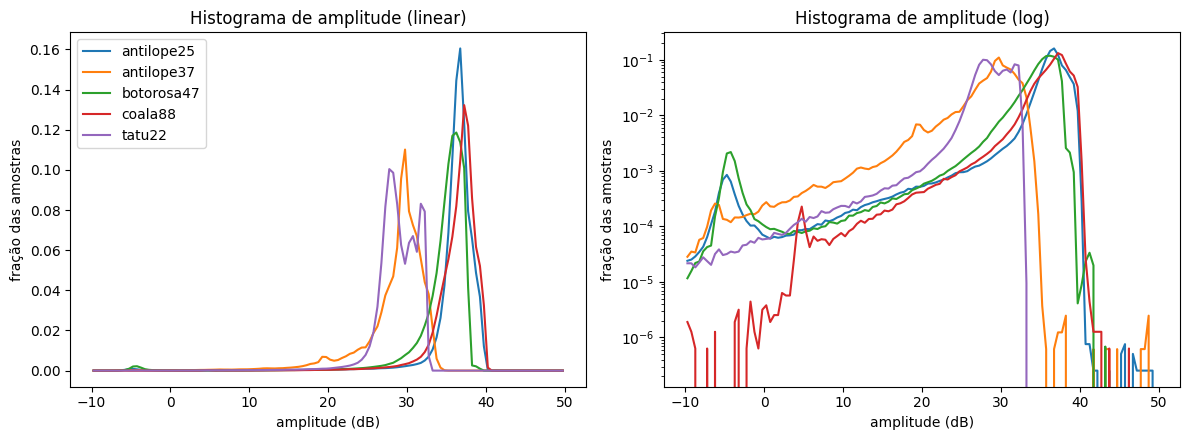

In [14]:
# Definindo as faixas de amplitude (dB) do histograma
bins = np.linspace(-10, 50, 121)

# Calculando o histograma de amplitude de cada poço (1 linha a cada 10, para ser mais rápido)
hist = {}
for p in pocos:
    df = load_well_image(p, img, verbose=False)
    v = df.values[::10]
    hist[p], _ = np.histogram(v, bins=bins)
    fora = int(((v < bins[0]) | (v > bins[-1])).sum())
    print(p, "| fora da faixa do histograma: %.3f%% | mín %.1f | máx %.1f" % (100 * fora / v.size, np.nanmin(v), np.nanmax(v)))
    del df, v

# Desenhando os histogramas normalizados dos 5 poços (escala linear e logarítmica)
centros = (bins[:-1] + bins[1:]) / 2
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, escala in zip(eixos, ["linear", "log"]):
    for p in pocos:
        ax.plot(centros, hist[p] / hist[p].sum(), label=p)
    ax.set_yscale(escala)
    ax.set_xlabel("amplitude (dB)")
    ax.set_ylabel("fração das amostras")
    ax.set_title(f"Histograma de amplitude ({escala})")
eixos[0].legend()
fig.tight_layout()

# Salvando o gráfico no Drive
os.makedirs(CARAC_DIR, exist_ok=True)
fig.savefig(f"{CARAC_DIR}/histograma_amplitude.png", dpi=100)
plt.show()

In [15]:
# Salvando as tabelas de caracterização no Drive
resumo.to_csv(f"{CARAC_DIR}/resumo_imagens.csv", index=False)
resumo_bsc.to_csv(f"{CARAC_DIR}/resumo_bsc.csv", index=False)
ausentes.to_csv(f"{CARAC_DIR}/ausentes_bsc.csv")
print(sorted(os.listdir(CARAC_DIR)))

['ausentes_bsc.csv', 'histograma_amplitude.png', 'normalizacao_por_poco.csv', 'patches_exemplo.png', 'patches_indice.csv', 'perfil_amplitude_media.png', 'resumo_bsc.csv', 'resumo_imagens.csv', 'zonas_excluidas_D1.csv', 'zonas_excluidas_D1.png']


### 1.7 Conversão para `.npy` e perfil de amplitude
Salvando cada poço em `.npy` e o perfil de amplitude média por linha.

antilope25: 219635 linhas x 180 colunas | profundidade 2061.13 a 2619.00 m | passo médio 0.00254 m | linhas por rótulo 3.94 | saltos: 0 | reordenado: não
  aviso: o rótulo de profundidade de antilope25 se repete em várias linhas (resolução do rótulo menor que o passo de amostragem). Use a posição da linha como eixo de profundidade, não o rótulo.
antilope37: 89982 linhas x 180 colunas | profundidade 2114.00 a 2571.11 m | passo médio 0.00508 m | linhas por rótulo 1.00 | saltos: 0 | reordenado: não
botorosa47: 81062 linhas x 180 colunas | profundidade 2178.00 a 2589.79 m | passo médio 0.00508 m | linhas por rótulo 1.97 | saltos: 0 | reordenado: não
  aviso: o rótulo de profundidade de botorosa47 se repete em várias linhas (resolução do rótulo menor que o passo de amostragem). Use a posição da linha como eixo de profundidade, não o rótulo.
coala88: 87796 linhas x 180 colunas | profundidade 2212.00 a 2658.00 m | passo médio 0.00508 m | linhas por rótulo 1.00 | saltos: 0 | reordenado: não
ta

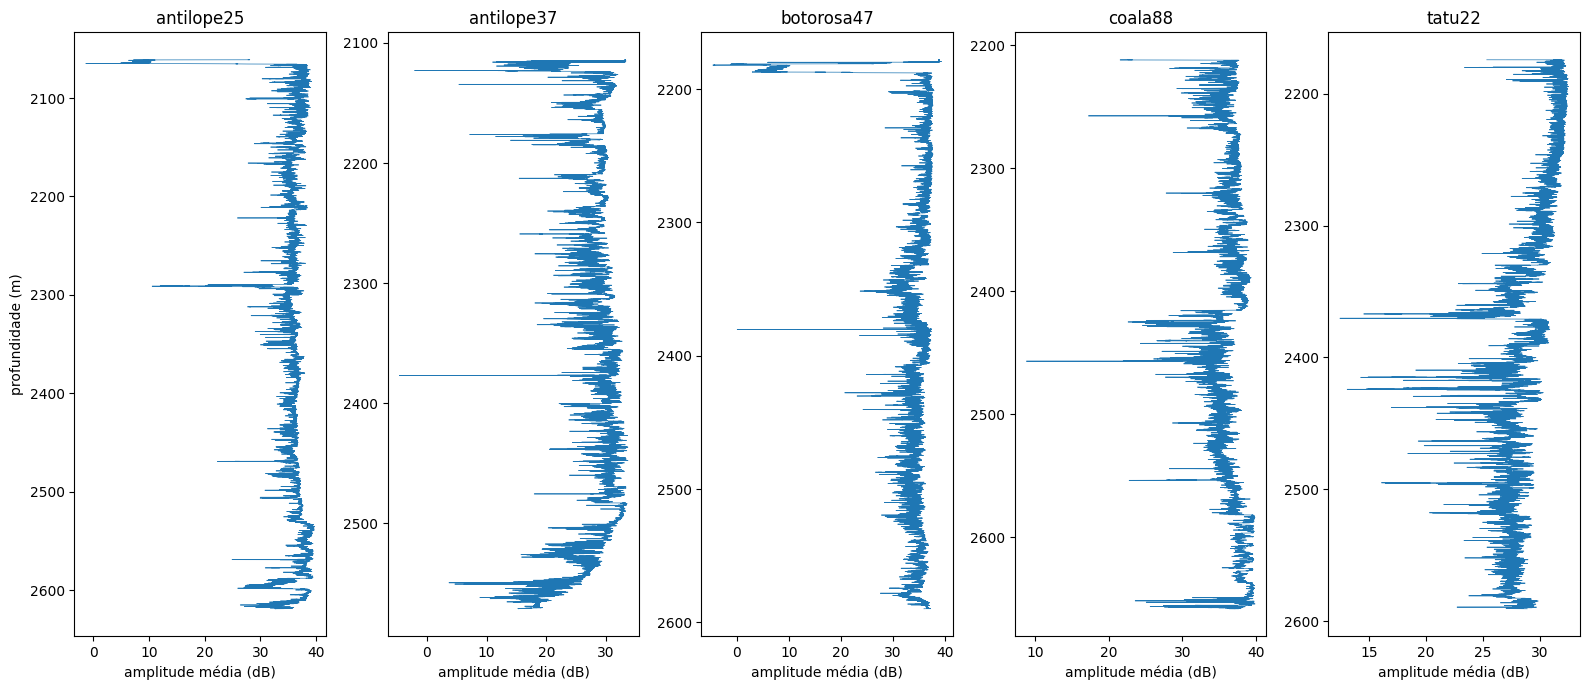

coala88 .npy: (87796, 180) float32 0.1 s


In [16]:
# Convertendo cada poço para .npy e calculando o perfil de amplitude média por linha
os.makedirs(NPY_DIR, exist_ok=True)
perfis, profs = {}, {}
for p in pocos:
    df = load_well_image(p, img)

    # Salvando a imagem (float32) e os rótulos de profundidade
    np.save(f"{NPY_DIR}/{p}_img.npy", df.values)
    np.save(f"{NPY_DIR}/{p}_prof.npy", df.index.values)

    # Calculando a amplitude média de cada linha e guardando o perfil
    perfis[p] = df.values.mean(axis=1)
    profs[p] = df.index.values
    np.save(f"{NPY_DIR}/{p}_perfil.npy", perfis[p])

    # Liberando a memória antes de carregar o próximo poço
    del df

# Desenhando o perfil de amplitude média por linha dos 5 poços (profundidade crescendo para baixo)
fig, eixos = plt.subplots(1, 5, figsize=(16, 7))
for ax, p in zip(eixos, pocos):
    ax.plot(perfis[p], profs[p], lw=0.5)
    ax.invert_yaxis()
    ax.set_title(p)
    ax.set_xlabel("amplitude média (dB)")
eixos[0].set_ylabel("profundidade (m)")
fig.tight_layout()

# Salvando o gráfico no Drive
os.makedirs(CARAC_DIR, exist_ok=True)
fig.savefig(f"{CARAC_DIR}/perfil_amplitude_media.png", dpi=100)
plt.show()

# Conferindo o tempo de leitura do .npy (poço coala88)
t0 = time.time()
x = np.load(f"{NPY_DIR}/coala88_img.npy")
print("coala88 .npy:", x.shape, x.dtype, f"{time.time() - t0:.1f} s")
del x

### 1.8 Exclusão das zonas anômalas (D1)
Marcando as zonas de artefato nas pontas de 3 poços.

      poco ponta  linha_ini  linha_fim  prof_ini_m  prof_fim_m  n_linhas  pct_do_poco
antilope25  topo          0       1641     2061.13     2065.29      1642         0.75
antilope37   fim      86735      89981     2554.62     2571.11      3247         3.61
botorosa47  topo          0       1895     2178.00     2187.63      1896         2.34


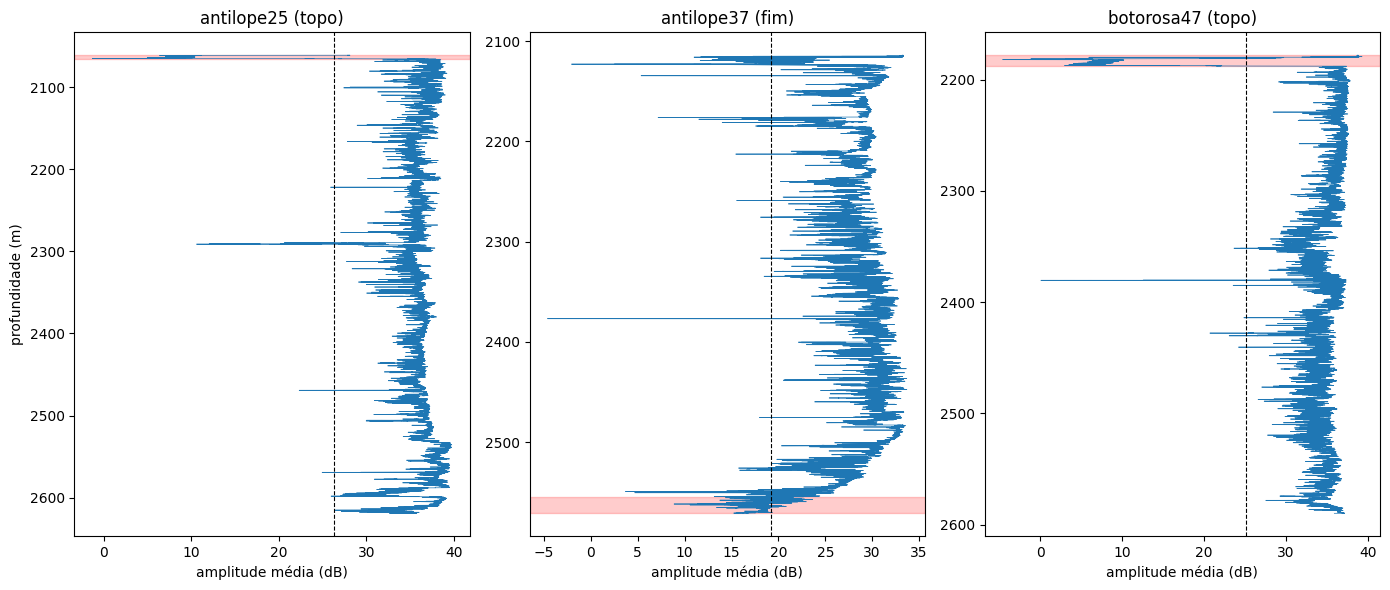

In [17]:
# Definindo os parâmetros da regra provisória de exclusão (decisão D1)
JANELA = 200       # linhas da média móvel do perfil de amplitude
FOLGA_DB = 10      # dB abaixo da mediana do perfil que definem "amplitude anômala"
TOLERANCIA = 500   # linhas normais seguidas que encerram a zona
ZONAS_D1 = {"antilope25": "topo", "antilope37": "fim", "botorosa47": "topo"}

# Aplicando a regra a cada ponta indicada e montando as máscaras (True = excluir)
linhas_zona = []
for p in pocos:
    perfil = np.load(f"{NPY_DIR}/{p}_perfil.npy")
    prof = np.load(f"{NPY_DIR}/{p}_prof.npy")
    n = len(perfil)
    suave = pd.Series(perfil).rolling(JANELA, center=True, min_periods=1).mean().values
    limite = np.median(perfil) - FOLGA_DB
    anomalo = suave < limite
    excluir = np.zeros(n, dtype=bool)
    ponta = ZONAS_D1.get(p)
    if ponta is not None:
        # Percorrendo a partir da ponta até achar TOLERANCIA linhas normais seguidas
        ordem = np.arange(n) if ponta == "topo" else np.arange(n - 1, -1, -1)
        ultima, normais = None, 0
        for i in ordem:
            if anomalo[i]:
                ultima, normais = i, 0
            else:
                normais += 1
                if normais >= TOLERANCIA:
                    break
        if ultima is not None:
            a, b = (0, ultima) if ponta == "topo" else (ultima, n - 1)
            excluir[a:b + 1] = True
            linhas_zona.append({"poco": p, "ponta": ponta, "linha_ini": int(a), "linha_fim": int(b),
                                "prof_ini_m": round(float(prof[a]), 2), "prof_fim_m": round(float(prof[b]), 2),
                                "n_linhas": int(b - a + 1), "pct_do_poco": round(100 * (b - a + 1) / n, 2)})
    np.save(f"{NPY_DIR}/{p}_excluir.npy", excluir)

# Imprimindo e salvando a tabela das zonas excluídas
zonas = pd.DataFrame(linhas_zona)
print(zonas.to_string(index=False))
zonas.to_csv(f"{CARAC_DIR}/zonas_excluidas_D1.csv", index=False)

# Desenhando o perfil das 3 pontas com a zona excluída em destaque
fig, eixos = plt.subplots(1, 3, figsize=(14, 6))
for ax, p in zip(eixos, ZONAS_D1):
    perfil = np.load(f"{NPY_DIR}/{p}_perfil.npy")
    prof = np.load(f"{NPY_DIR}/{p}_prof.npy")
    excluir = np.load(f"{NPY_DIR}/{p}_excluir.npy")
    ax.plot(perfil, prof, lw=0.5)
    if excluir.any():
        ax.axhspan(prof[excluir].min(), prof[excluir].max(), color="red", alpha=0.2)
    ax.axvline(np.median(perfil) - FOLGA_DB, color="k", ls="--", lw=0.8)
    ax.invert_yaxis()
    ax.set_title(f"{p} ({ZONAS_D1[p]})")
    ax.set_xlabel("amplitude média (dB)")
eixos[0].set_ylabel("profundidade (m)")
fig.tight_layout()
fig.savefig(f"{CARAC_DIR}/zonas_excluidas_D1.png", dpi=100)
plt.show()

### 1.9 Normalização e patches (D2, D3 e D4)
Reamostrando o antilope25, normalizando por poço e gerando patches de 256 × 180.

      poco  fator_vertical  linhas  p_baixo_db  p_alto_db  patches_possiveis  patches_validos
antilope25               2  109817       21.75      39.54                856              849
antilope37               1   89982       11.27      33.42                701              676
botorosa47               1   81062       23.44      37.80                632              617
   coala88               1   87796       24.07      39.79                684              684
    tatu22               1   81983       17.98      32.46                639              639
total de patches válidos: 3465


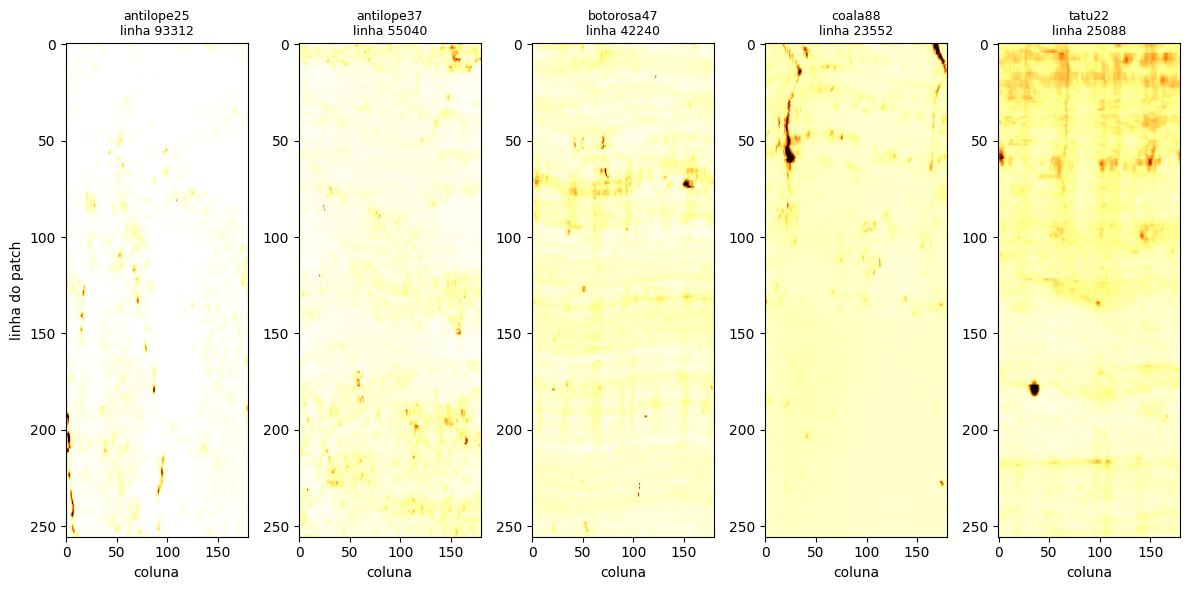

In [18]:
# Definindo os parâmetros da normalização e dos patches (decisões D2, D3 e D4)
FATOR_VERTICAL = {"antilope25": 2}   # D2: média de N linhas, para igualar o passo de 0,00508 m
PERCENTIS = (1, 99)                  # D3: percentis do poço, calculados sem as zonas da D1
ALTURA_PATCH = 256                   # D4: linhas por patch (o patch usa as 180 colunas)
PASSO_PATCH = 128                    # D4: passo entre patches (sobreposição de 50%)

# Reamostrando, normalizando cada poço e listando os patches que não tocam zonas excluídas
param_norm, patches = [], []
for p in pocos:
    img_p = np.load(f"{NPY_DIR}/{p}_img.npy")
    excl = np.load(f"{NPY_DIR}/{p}_excluir.npy")
    prof = np.load(f"{NPY_DIR}/{p}_prof.npy")

    # D2: reamostrando na vertical (uma linha nova é excluída se qualquer linha original for)
    f = FATOR_VERTICAL.get(p, 1)
    if f > 1:
        n = (len(img_p) // f) * f
        img_p = img_p[:n].reshape(-1, f, img_p.shape[1]).mean(axis=1)
        excl = excl[:n].reshape(-1, f).any(axis=1)
        prof = prof[:n].reshape(-1, f).mean(axis=1)

    # D3: calculando os percentis sem as linhas excluídas e normalizando para [0, 1]
    p_baixo, p_alto = np.percentile(img_p[~excl][::10], PERCENTIS)
    norm = np.clip((img_p - p_baixo) / (p_alto - p_baixo), 0, 1).astype(np.float16)
    np.save(f"{NPY_DIR}/{p}_norm.npy", norm)
    np.save(f"{NPY_DIR}/{p}_excluir_rs.npy", excl)
    np.save(f"{NPY_DIR}/{p}_prof_rs.npy", prof)

    # D4: listando os patches válidos
    possiveis = 0
    for ini in range(0, len(norm) - ALTURA_PATCH + 1, PASSO_PATCH):
        possiveis += 1
        if not excl[ini:ini + ALTURA_PATCH].any():
            patches.append({"poco": p, "linha_ini": ini,
                            "prof_ini_m": round(float(prof[ini]), 2),
                            "prof_fim_m": round(float(prof[ini + ALTURA_PATCH - 1]), 2)})
    validos = sum(1 for x in patches if x["poco"] == p)
    param_norm.append({"poco": p, "fator_vertical": f, "linhas": len(norm),
                       "p_baixo_db": round(float(p_baixo), 2), "p_alto_db": round(float(p_alto), 2),
                       "patches_possiveis": possiveis, "patches_validos": validos})
    del img_p, norm

# Imprimindo e salvando as tabelas de normalização e de patches
tab_norm = pd.DataFrame(param_norm)
tab_patches = pd.DataFrame(patches)
print(tab_norm.to_string(index=False))
print("total de patches válidos:", len(tab_patches))
tab_norm.to_csv(f"{CARAC_DIR}/normalizacao_por_poco.csv", index=False)
tab_patches.to_csv(f"{CARAC_DIR}/patches_indice.csv", index=False)

# Desenhando um patch sorteado de cada poço para conferir a escala visual
rng = np.random.default_rng(0)
fig, eixos = plt.subplots(1, 5, figsize=(12, 6))
for ax, p in zip(eixos, pocos):
    norm = np.load(f"{NPY_DIR}/{p}_norm.npy", mmap_mode="r")
    linha = int(rng.choice(tab_patches[tab_patches.poco == p].linha_ini.values))
    ax.imshow(np.asarray(norm[linha:linha + ALTURA_PATCH], dtype=np.float32), aspect="auto", cmap="afmhot", vmin=0, vmax=1)
    ax.set_title(f"{p}\nlinha {linha}", fontsize=9)
    ax.set_xlabel("coluna")
eixos[0].set_ylabel("linha do patch")
fig.tight_layout()
fig.savefig(f"{CARAC_DIR}/patches_exemplo.png", dpi=100)
plt.show()